1. RF classifier 
2. Y2H betweenness centrality percentile 

In [1]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import mannwhitneyu
from scipy.stats import spearmanr, pearsonr
from tqdm import trange
import matplotlib.ticker as ticker
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)
import shap

DATA_PATH3 = "../../17-meltome-atlas/processed-data/"
Y2H_COLOR  = "#BB5566"

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.titlesize": 14,
    "axes.titlepad": 25,
    "font.family": "sans-serif",
    "font.sans-serif": "Arial",
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

In [2]:
# load the datasets with node centrality information and get nodes 
y2h_nodes = pd.read_pickle(f"{DATA_PATH3}y2h-test-s288c-step17.pkl")
print(f"Total proteins in the original y2h network: {len(y2h_nodes)}")

Total proteins in the original y2h network: 2018


In [3]:
# determine which nodes are bottleneck based on percentile cutoff for betweenness centrality
cut = 0.10
y2h_threshold = y2h_nodes["betweenness_centrality"].quantile(1 - cut)
y2h_hubs = y2h_nodes[y2h_nodes["betweenness_centrality"] >= y2h_threshold]
y2h_nothub  = y2h_nodes[y2h_nodes["betweenness_centrality"] <  y2h_threshold]

print (f"Threshold for defining a bottleneck in y2h data is {y2h_threshold:.5f}; there are {len(y2h_hubs)} bottleneck and {len(y2h_nothub)} non bottleneck")

Threshold for defining a bottleneck in y2h data is 0.00366; there are 202 bottleneck and 1816 non bottleneck


In [4]:
# --- Flip sign of cagiada-dG ---
y2h_nodes["cagiada-dG"] = -y2h_nodes["cagiada-dG"]

In [5]:
# CHAPERONE CATEGORY: three-way classification ===
# 1. Standardize interacting_chaperones lists
def fix_list(val):
    if isinstance(val, list):
        return val
    elif isinstance(val, str):
        try:
            parsed = ast.literal_eval(val)
            return parsed if isinstance(parsed, list) else []
        except (ValueError, SyntaxError):
            return []
    else:
        return []

y2h_nodes["interacting_chaperones"] = (
    y2h_nodes["interacting_chaperones"].apply(fix_list)
)


# 2. Identify unique annotated chaperones
chaperone_ids = {
    chap
    for chaps in y2h_nodes["interacting_chaperones"]
    for chap in chaps
}

print(f"Unique annotated chaperones: {len(chaperone_ids)}")


# 3. Create two INDEPENDENT binary attributes

# Is this protein a chaperone?
y2h_nodes["is_chaperone"] = (
    y2h_nodes["node"].isin(chaperone_ids)
).astype(int)

# Does this protein interact with a chaperone?
y2h_nodes["interacts_with_chaperone"] = (
    y2h_nodes["interacting_chaperones"].apply(lambda x: len(x) > 0)
).astype(int)


# 4. Create mutually exclusive categories
y2h_nodes["chaperone_category"] = np.select(
    [
        y2h_nodes["is_chaperone"] == 1,
        y2h_nodes["interacts_with_chaperone"] == 1
    ],
    [
        "protein_is_chaperone",
        "protein_interacts_with_chaperone"
    ],
    default="protein_is_neither_chaperone_nor_interacts"
)


# 5. Retain the neither-category indicator
y2h_nodes["neither_chaperone_nor_interacts"] = (
    y2h_nodes["chaperone_category"]
    == "protein_is_neither_chaperone_nor_interacts"
).astype(int)


# 6. Verify classifications
print("\nChaperone category counts:")
print(y2h_nodes["chaperone_category"].value_counts())

print("\nProteins with at least one chaperone interaction:")
print(y2h_nodes["interacts_with_chaperone"].sum())

print("\nChaperones that also interact with chaperones:")
print(
    (
        (y2h_nodes["is_chaperone"] == 1)
        & (y2h_nodes["interacts_with_chaperone"] == 1)
    ).sum()
)

Unique annotated chaperones: 28

Chaperone category counts:
chaperone_category
protein_is_neither_chaperone_nor_interacts    1958
protein_interacts_with_chaperone                32
protein_is_chaperone                            28
Name: count, dtype: int64

Proteins with at least one chaperone interaction:
51

Chaperones that also interact with chaperones:
19


In [6]:
# Track how many proteins remain at each filtering step
summary_rows = []

def record_stage(df, stage, previous_count):
    summary_rows.append({
        "stage": stage,
        "total_remaining": len(df),
        "removed_at_step": previous_count - len(df),
        "bottleneck": int((df["betweenness_centrality"] >= y2h_threshold).sum()),
        "non_bottleneck": int((df["betweenness_centrality"] < y2h_threshold).sum()),
        "missing_betweenness": int(df["betweenness_centrality"].isna().sum()),
        "ghosh_dill_nonnull": int(df["Ghosh-Dill-dG"].notna().sum()),
        "cagiada_nonnull": int(df["cagiada-dG"].notna().sum()),
        "rosetta_nonnull": int(df["Rosetta_best_total_score"].notna().sum()),
    })

    for category, count in (
        df["DeepTMHMM_class"].fillna("Missing").value_counts().items()
    ):
        summary_rows[-1][f"class_{category}"] = int(count)

# Start with the complete Y2H network
filtered_nodes = y2h_nodes.copy()
record_stage(filtered_nodes, "Before filtering", len(filtered_nodes))

# Step 1: Keep proteins with pLDDT >= 70
previous_count = len(filtered_nodes)
filtered_nodes = filtered_nodes[
    filtered_nodes["mean_plddt"] >= 70
].copy()
record_stage(filtered_nodes, "After pLDDT >= 70", previous_count)

# Step 2: Remove TM, SP+TM, and BETA proteins sequentially
for category in ["TM", "SP+TM", "BETA"]:
    previous_count = len(filtered_nodes)
    filtered_nodes = filtered_nodes[
        ~filtered_nodes["DeepTMHMM_class"].isin([category])
    ].copy()
    record_stage(
        filtered_nodes,
        f"After removing {category}",
        previous_count,
    )

# Generate filtering summary
filtering_summary = pd.DataFrame(summary_rows).fillna(0)

count_columns = filtering_summary.columns.drop("stage")
filtering_summary[count_columns] = (
    filtering_summary[count_columns].astype(int)
)

display(filtering_summary)


,stage,total_remaining,removed_at_step,bottleneck,non_bottleneck,missing_betweenness,ghosh_dill_nonnull,cagiada_nonnull,rosetta_nonnull,class_GLOB,class_TM,class_Missing,class_SP,class_SP+TM
0,Before filtering,2018,0,202,1816,0,1752,1752,1752,1724,193,58,33,10
1,After pLDDT >= 70,1426,592,144,1282,0,1268,1268,1268,1245,151,0,23,7
2,After removing TM,1275,151,133,1142,0,1268,1268,1268,1245,0,0,23,7
3,After removing SP+TM,1268,7,133,1135,0,1268,1268,1268,1245,0,0,23,0
4,After removing BETA,1268,0,133,1135,0,1268,1268,1268,1245,0,0,23,0


In [7]:
# Identify bottleneck and non-bottleneck in the filtered Y2H network
# Keep the original Y2H betweenness_centrality threshold

filtered_y2h_hubs = filtered_nodes[
    filtered_nodes["betweenness_centrality"] >= y2h_threshold
].copy()

filtered_y2h_nothub = filtered_nodes[
    filtered_nodes["betweenness_centrality"] < y2h_threshold
].copy()

# Verify that every retained protein has a betweenness_centrality value
assert filtered_nodes["betweenness_centrality"].notna().all()

# Print the final classification
print(f"Original Y2H bottleneck threshold: {y2h_threshold:.5f}")
print(f"Filtered Y2H bottleneck: {len(filtered_y2h_hubs)}")
print(f"Filtered Y2H non-bottleneck: {len(filtered_y2h_nothub)}")
print(f"Total filtered proteins: {len(filtered_nodes)}")
print(f"Bottleneck percentage: {len(filtered_y2h_hubs) / len(filtered_nodes) * 100:.2f}%")


Original Y2H bottleneck threshold: 0.00366
Filtered Y2H bottleneck: 133
Filtered Y2H non-bottleneck: 1135
Total filtered proteins: 1268
Bottleneck percentage: 10.49%


In [8]:
# ============================================================
# 1. Create the binary target variable
# ============================================================

filtered_nodes["y2h_hubs"] = (
    filtered_nodes["betweenness_centrality"] >= y2h_threshold
).astype(int)

print("Target variable distribution:")
print(filtered_nodes["y2h_hubs"].value_counts())

# Verify consistency 
assert filtered_nodes["y2h_hubs"].sum() == len(filtered_y2h_hubs)

Target variable distribution:
y2h_hubs
0    1135
1     133
Name: count, dtype: int64


In [9]:
# ============================================================
# 2. Define Random Forest predictor features
# ============================================================

ml_features = [
    "Ghosh-Dill-dG",
    "cagiada-dG",
    "Rosetta_best_total_score",
    "Villen_halflife_min",
    "mean_molecules_per_cell",
    "interacts_with_chaperone",
    "in_complex",
    "essential",
    "meltome-melting-point",
    "N_aa_disordered",
    "disorder_fraction",
    "mean_plddt"
]

X = filtered_nodes[ml_features].copy()
y = filtered_nodes["y2h_hubs"].copy()

# ============================================================
# 3. Convert predictor features to numeric values
# ============================================================

missing_indicators = [
    "n.d.", "N.D.", "nd", "ND", "na", "NA",
    "null", "NULL", "missing", "MISSING",
    "-", "n/a", "N/A", ""
]

for col in ml_features:
    X[col] = X[col].replace(missing_indicators, np.nan)
    X[col] = pd.to_numeric(X[col], errors="coerce")


# ============================================================
# 4. Examine missing predictor values
# ============================================================

print("\nMissing values by predictor:")
print(X.isna().sum().sort_values(ascending=False))


# ============================================================
# 5. Preserve original missing-value encoding
# ============================================================

#X_filled = X.fillna(-999)


# ============================================================
# 6. Final verification
# ============================================================

print("\nData preparation complete")
print(f"Total samples: {len(X)}")
print(f"Number of predictors: {X.shape[1]}")
print(f"Bottlenecks: {int(y.sum())}")
print(f"Non-bottlenecks: {int((y == 0).sum())}")


Missing values by predictor:
meltome-melting-point       658
Villen_halflife_min         437
mean_molecules_per_cell      24
Ghosh-Dill-dG                 0
Rosetta_best_total_score      0
cagiada-dG                    0
in_complex                    0
interacts_with_chaperone      0
essential                     0
N_aa_disordered               0
disorder_fraction             0
mean_plddt                    0
dtype: int64

Data preparation complete
Total samples: 1268
Number of predictors: 12
Bottlenecks: 133
Non-bottlenecks: 1135


In [10]:
# Examine missing data separately for bottlenecks and non-bottlenecks

missingness_summary = pd.DataFrame({
    "Missing (n)": X.isna().sum(),
    "Missing (%)": X.isna().mean() * 100,
    "Non-bottlenecks missing (%)": X.loc[y == 0].isna().mean() * 100,
    "Bottleneck missing (%)": X.loc[y == 1].isna().mean() * 100
})

# Display only predictors with missing values
missingness_summary = missingness_summary[
    missingness_summary["Missing (n)"] > 0
]

display(missingness_summary.round(2))


,Missing (n),Missing (%),Non-bottlenecks missing (%),Bottleneck missing (%)
Villen_halflife_min,437,34.46,34.27,36.09
mean_molecules_per_cell,24,1.89,1.94,1.50
meltome-melting-point,658,51.89,51.10,58.65


In [11]:
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve, confusion_matrix
)

# -------------------------------------------
# Repeated train/test evaluation
# -------------------------------------------

n_models = 50
test_size = 0.2
base_random_state = 42

splitter = StratifiedShuffleSplit(
    n_splits=n_models,
    test_size=test_size,
    random_state=base_random_state
)

results = []
feature_importances_list = []
roc_curves = []

fpr_grid = np.linspace(0, 1, 100)

last_model = None
last_X_test = None
last_y_test = None

# -------------------------------------------
# Train 50 Random Forest models
# -------------------------------------------

for i, (train_idx, test_idx) in enumerate(
    splitter.split(X, y), start=1
):

    # Split the original data (NaNs preserved)
    X_train_raw = X.iloc[train_idx].copy()
    X_test_raw = X.iloc[test_idx].copy()

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Fit median imputation on training data only
    imputer = SimpleImputer(strategy="median")

    X_train = pd.DataFrame(
        imputer.fit_transform(X_train_raw),
        columns=X.columns,
        index=X_train_raw.index
    )

    X_test = pd.DataFrame(
        imputer.transform(X_test_raw),
        columns=X.columns,
        index=X_test_raw.index
    )

    # Initialize Random Forest
    rf_model = RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        class_weight="balanced",
        random_state=base_random_state + i
    )

    # Train model
    rf_model.fit(X_train, y_train)

    # Predict test data
    y_pred = rf_model.predict(X_test)
    y_proba = rf_model.predict_proba(X_test)[:, 1]

    # Calculate performance metrics
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)

    interp_tpr = np.interp(fpr_grid, fpr, tpr)
    interp_tpr[0] = 0.0
    interp_tpr[-1] = 1.0

    roc_curves.append(interp_tpr)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Store metrics
    results.append({
        "model_num": i,
        "balanced_accuracy": bal_acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    })

    # Store feature importance
    feature_importances_list.append(
        rf_model.feature_importances_
    )

    # Retain last model for subsequent analysis
    last_model = rf_model
    last_X_test = X_test.copy()
    last_y_test = y_test.copy()

# -------------------------------------------
# Summarize results
# -------------------------------------------

results_df = pd.DataFrame(results)

print("50-model evaluation complete")
print(results_df.describe())

50-model evaluation complete
       model_num  balanced_accuracy  precision     recall         f1  \
count   50.00000          50.000000  50.000000  50.000000  50.000000   
mean    25.50000           0.550780   0.188245   0.210370   0.196811   
std     14.57738           0.034812   0.055559   0.069969   0.058080   
min      1.00000           0.466552   0.058824   0.074074   0.065574   
25%     13.25000           0.533121   0.155925   0.185185   0.169643   
50%     25.50000           0.557595   0.196154   0.203704   0.209741   
75%     37.75000           0.574013   0.227880   0.259259   0.236299   
max     50.00000           0.623511   0.307692   0.370370   0.307692   

         roc_auc         tn        fp         fn         tp  
count  50.000000   50.00000  50.00000  50.000000  50.000000  
mean    0.616567  202.30000  24.70000  21.320000   5.680000  
std     0.050856    5.00306   5.00306   1.889174   1.889174  
min     0.497145  191.00000  14.00000  17.000000   2.000000  
25%     0.58

In [12]:
metrics_to_summarize = ["balanced_accuracy", "precision", "recall", "f1", "roc_auc"]

print("\nModel Performance Across 50 Runs:")
for metric in metrics_to_summarize:
    mean_val = results_df[metric].mean()
    std_val = results_df[metric].std()
    print(f"{metric}: {mean_val:.3f} ± {std_val:.3f}")


Model Performance Across 50 Runs:
balanced_accuracy: 0.551 ± 0.035
precision: 0.188 ± 0.056
recall: 0.210 ± 0.070
f1: 0.197 ± 0.058
roc_auc: 0.617 ± 0.051


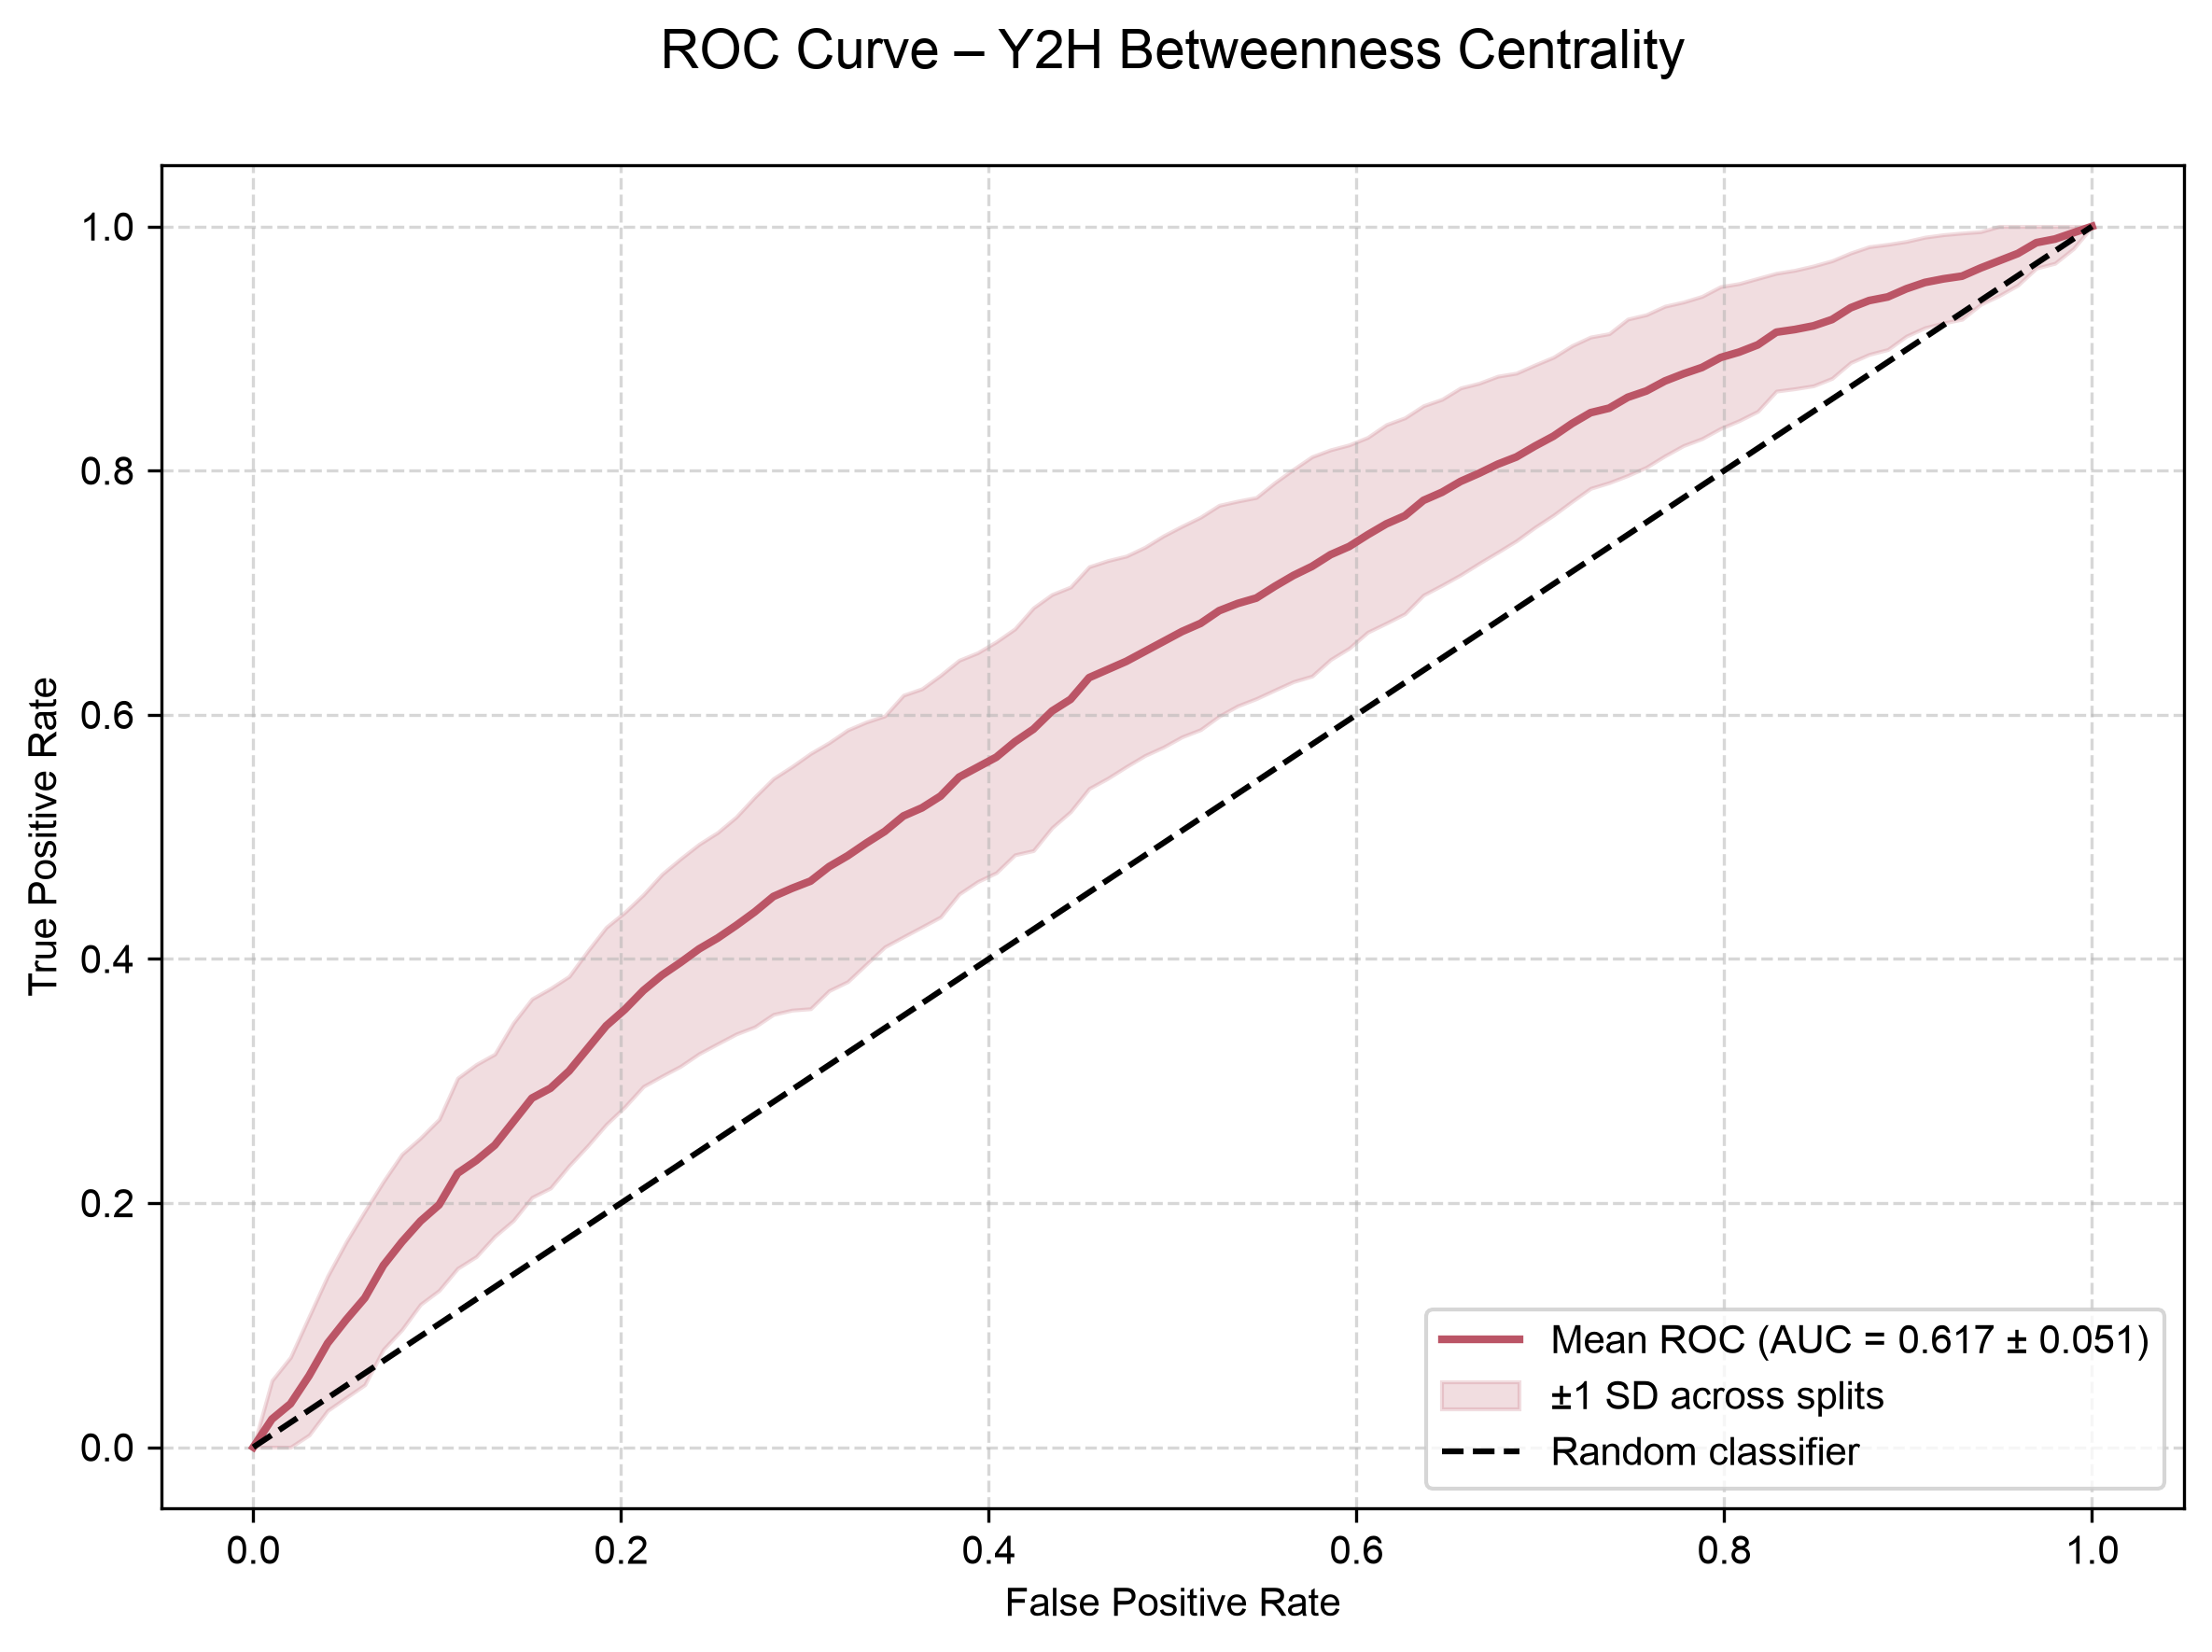

Mean ROC-AUC: 0.617 ± 0.051


In [13]:
# ============================================================
# Calculate mean ROC curve across 50 models
# ============================================================

roc_array = np.array(roc_curves)

mean_tpr = roc_array.mean(axis=0)
std_tpr = roc_array.std(axis=0, ddof=1)

mean_auc = results_df["roc_auc"].mean()
std_auc = results_df["roc_auc"].std()


# ============================================================
# Export ROC curve data
# ============================================================

roc_export_df = pd.DataFrame({
    "False_Positive_Rate": fpr_grid,
    "Mean_True_Positive_Rate": mean_tpr,
    "SD_True_Positive_Rate": std_tpr
})

roc_export_df.to_csv(
    "roc_Y2H_betweenness_50models.csv",
    index=False
)


# ============================================================
# Plot mean ROC curve
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_grid,
    mean_tpr,
    color=Y2H_COLOR,
    linewidth=2,
    label=f"Mean ROC (AUC = {mean_auc:.3f} ± {std_auc:.3f})"
)

# Variability across 50 train/test splits
plt.fill_between(
    fpr_grid,
    np.maximum(mean_tpr - std_tpr, 0),
    np.minimum(mean_tpr + std_tpr, 1),
    color=Y2H_COLOR,
    alpha=0.2,
    label="±1 SD across splits"
)

# Random classifier reference
plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Y2H Betweenness Centrality")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Mean ROC-AUC: {mean_auc:.3f} ± {std_auc:.3f}")


In [14]:
# ============================================================
# 1. Collect Gini feature importance from all 50 models
# ============================================================

feature_importances_array = np.array(feature_importances_list)


# ============================================================
# 2. Calculate mean and SD across 50 models
# ============================================================

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Mean_Gini_Importance": feature_importances_array.mean(axis=0),
    "SD_Gini_Importance": feature_importances_array.std(axis=0, ddof=1)
}).sort_values(
    by="Mean_Gini_Importance",
    ascending=False
)


# ============================================================
# 3. Display results
# ============================================================

print("\nMean Gini Feature Importances Across 50 Runs:")
print(importance_df.to_string(index=False))



Mean Gini Feature Importances Across 50 Runs:
                 Feature  Mean_Gini_Importance  SD_Gini_Importance
     Villen_halflife_min              0.129682            0.011852
              mean_plddt              0.128328            0.008623
 mean_molecules_per_cell              0.114853            0.012024
           Ghosh-Dill-dG              0.111906            0.008155
              cagiada-dG              0.102003            0.007512
Rosetta_best_total_score              0.096102            0.005796
         N_aa_disordered              0.093606            0.006707
       disorder_fraction              0.077402            0.005956
   meltome-melting-point              0.072561            0.005465
interacts_with_chaperone              0.033243            0.010157
               essential              0.021314            0.004339
              in_complex              0.019000            0.005300


In [15]:
# ============================================================
# SHAP ANALYSIS ACROSS ALL 50 RANDOM FOREST MODELS
# Y2H betweenness_centrality
# ============================================================

from sklearn.impute import SimpleImputer

# Display names for figures
rename_map = {
    "Ghosh-Dill-dG": "Ghosh & Dill 2010 ΔG(L, T)",
    "cagiada-dG": "Cagiada et al. 2025 ΔG",
    "Rosetta_best_total_score": "Rosetta total score (REU)",
    "Villen_halflife_min": "Protein half-life (min)",
    "mean_molecules_per_cell": "Molecular abundance",
    "interacts_with_chaperone": "Chaperone interaction",
    "in_complex": "In complex",
    "essential": "Essential",
    "meltome-melting-point": "Melting point (°C)",
    "N_aa_disordered": r"$N_{\mathrm{disordered}}$",
    "disorder_fraction": "Disorder fraction",
    "mean_plddt": "Mean pLDDT"
}

# Reproduce the same train/test splits used
splitter_shap = StratifiedShuffleSplit(
    n_splits=n_models,
    test_size=test_size,
    random_state=base_random_state
)

# Storage for SHAP results
mean_abs_shap_list = []
all_shap_values = []
all_X_test = []

print("Computing SHAP across all 50 models...")

for i, (train_idx, test_idx) in enumerate(
    splitter_shap.split(X, y), start=1
):

    # ----------------------------------------
    # 1. Split original data
    # ----------------------------------------

    X_train_raw = X.iloc[train_idx].copy()
    X_test_raw = X.iloc[test_idx].copy()

    y_train = y.iloc[train_idx]

    # ----------------------------------------
    # 2. Impute missing values using training data
    # ----------------------------------------

    imputer = SimpleImputer(strategy="median")

    X_train = pd.DataFrame(
        imputer.fit_transform(X_train_raw),
        columns=X.columns,
        index=X_train_raw.index
    )

    X_test = pd.DataFrame(
        imputer.transform(X_test_raw),
        columns=X.columns,
        index=X_test_raw.index
    )

    # ----------------------------------------
    # 3. Recreate the Random Forest model
    # ----------------------------------------

    rf_model = RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        class_weight="balanced",
        random_state=base_random_state + i
    )

    rf_model.fit(X_train, y_train)

    # ----------------------------------------
    # 4. Calculate SHAP values
    # ----------------------------------------

    explainer = shap.TreeExplainer(rf_model)
    shap_values = explainer.shap_values(X_test)

    # Extract SHAP values for class 1 (bottleneck)
    if isinstance(shap_values, list):
        shap_class_values = shap_values[1]

    elif np.asarray(shap_values).ndim == 3:
        shap_class_values = shap_values[:, :, 1]

    else:
        shap_class_values = shap_values

    shap_class_values = np.asarray(shap_class_values)

    assert shap_class_values.shape == X_test.shape

    # ----------------------------------------
    # 5. Mean absolute SHAP per model
    # ----------------------------------------

    mean_abs_shap = np.abs(shap_class_values).mean(axis=0)

    mean_abs_shap_list.append(mean_abs_shap)

    # Store test-set SHAP values for beeswarm
    all_shap_values.append(shap_class_values)
    all_X_test.append(X_test.copy())

    if i % 10 == 0:
        print(f"Completed {i}/{n_models} models")

print("\nSHAP calculation across 50 models completed.")
print(f"Stored models: {len(mean_abs_shap_list)}")
print(f"Number of features: {len(ml_features)}")

Computing SHAP across all 50 models...
Completed 10/50 models
Completed 20/50 models
Completed 30/50 models
Completed 40/50 models
Completed 50/50 models

SHAP calculation across 50 models completed.
Stored models: 50
Number of features: 12


In [16]:
# ============================================================
# SUMMARIZE MEAN ABSOLUTE SHAP ACROSS 50 MODELS
# ============================================================

# 1. Collect SHAP importance from all 50 models
mean_abs_shap_array = np.array(mean_abs_shap_list)

# 2. Verify dimensions: 50 models × 12 predictors
assert mean_abs_shap_array.shape == (n_models, len(ml_features))

# 3. Calculate mean and standard deviation
shap_importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Display_Name": [rename_map.get(f, f) for f in X.columns],
    "Mean_Abs_SHAP": mean_abs_shap_array.mean(axis=0),
    "SD_Abs_SHAP": mean_abs_shap_array.std(axis=0, ddof=1)
}).sort_values(
    by="Mean_Abs_SHAP",
    ascending=False
)

# 4. Display results
print("\nMean Absolute SHAP Across 50 Models:")
print(shap_importance_df.to_string(index=False))

# 5. Export results
shap_importance_df.to_csv(
    "mean_abs_shap_Y2H_betweenness_50models.csv",
    index=False
)


Mean Absolute SHAP Across 50 Models:
                 Feature               Display_Name  Mean_Abs_SHAP  SD_Abs_SHAP
     Villen_halflife_min    Protein half-life (min)       0.045353     0.008305
         N_aa_disordered  $N_{\mathrm{disordered}}$       0.037574     0.008106
           Ghosh-Dill-dG Ghosh & Dill 2010 ΔG(L, T)       0.031687     0.006153
              mean_plddt                 Mean pLDDT       0.030216     0.005071
 mean_molecules_per_cell        Molecular abundance       0.026695     0.005799
              cagiada-dG     Cagiada et al. 2025 ΔG       0.026379     0.005419
       disorder_fraction          Disorder fraction       0.022276     0.005094
              in_complex                 In complex       0.019217     0.008683
Rosetta_best_total_score  Rosetta total score (REU)       0.018487     0.002348
               essential                  Essential       0.017350     0.006159
interacts_with_chaperone      Chaperone interaction       0.017195     0.004901
  

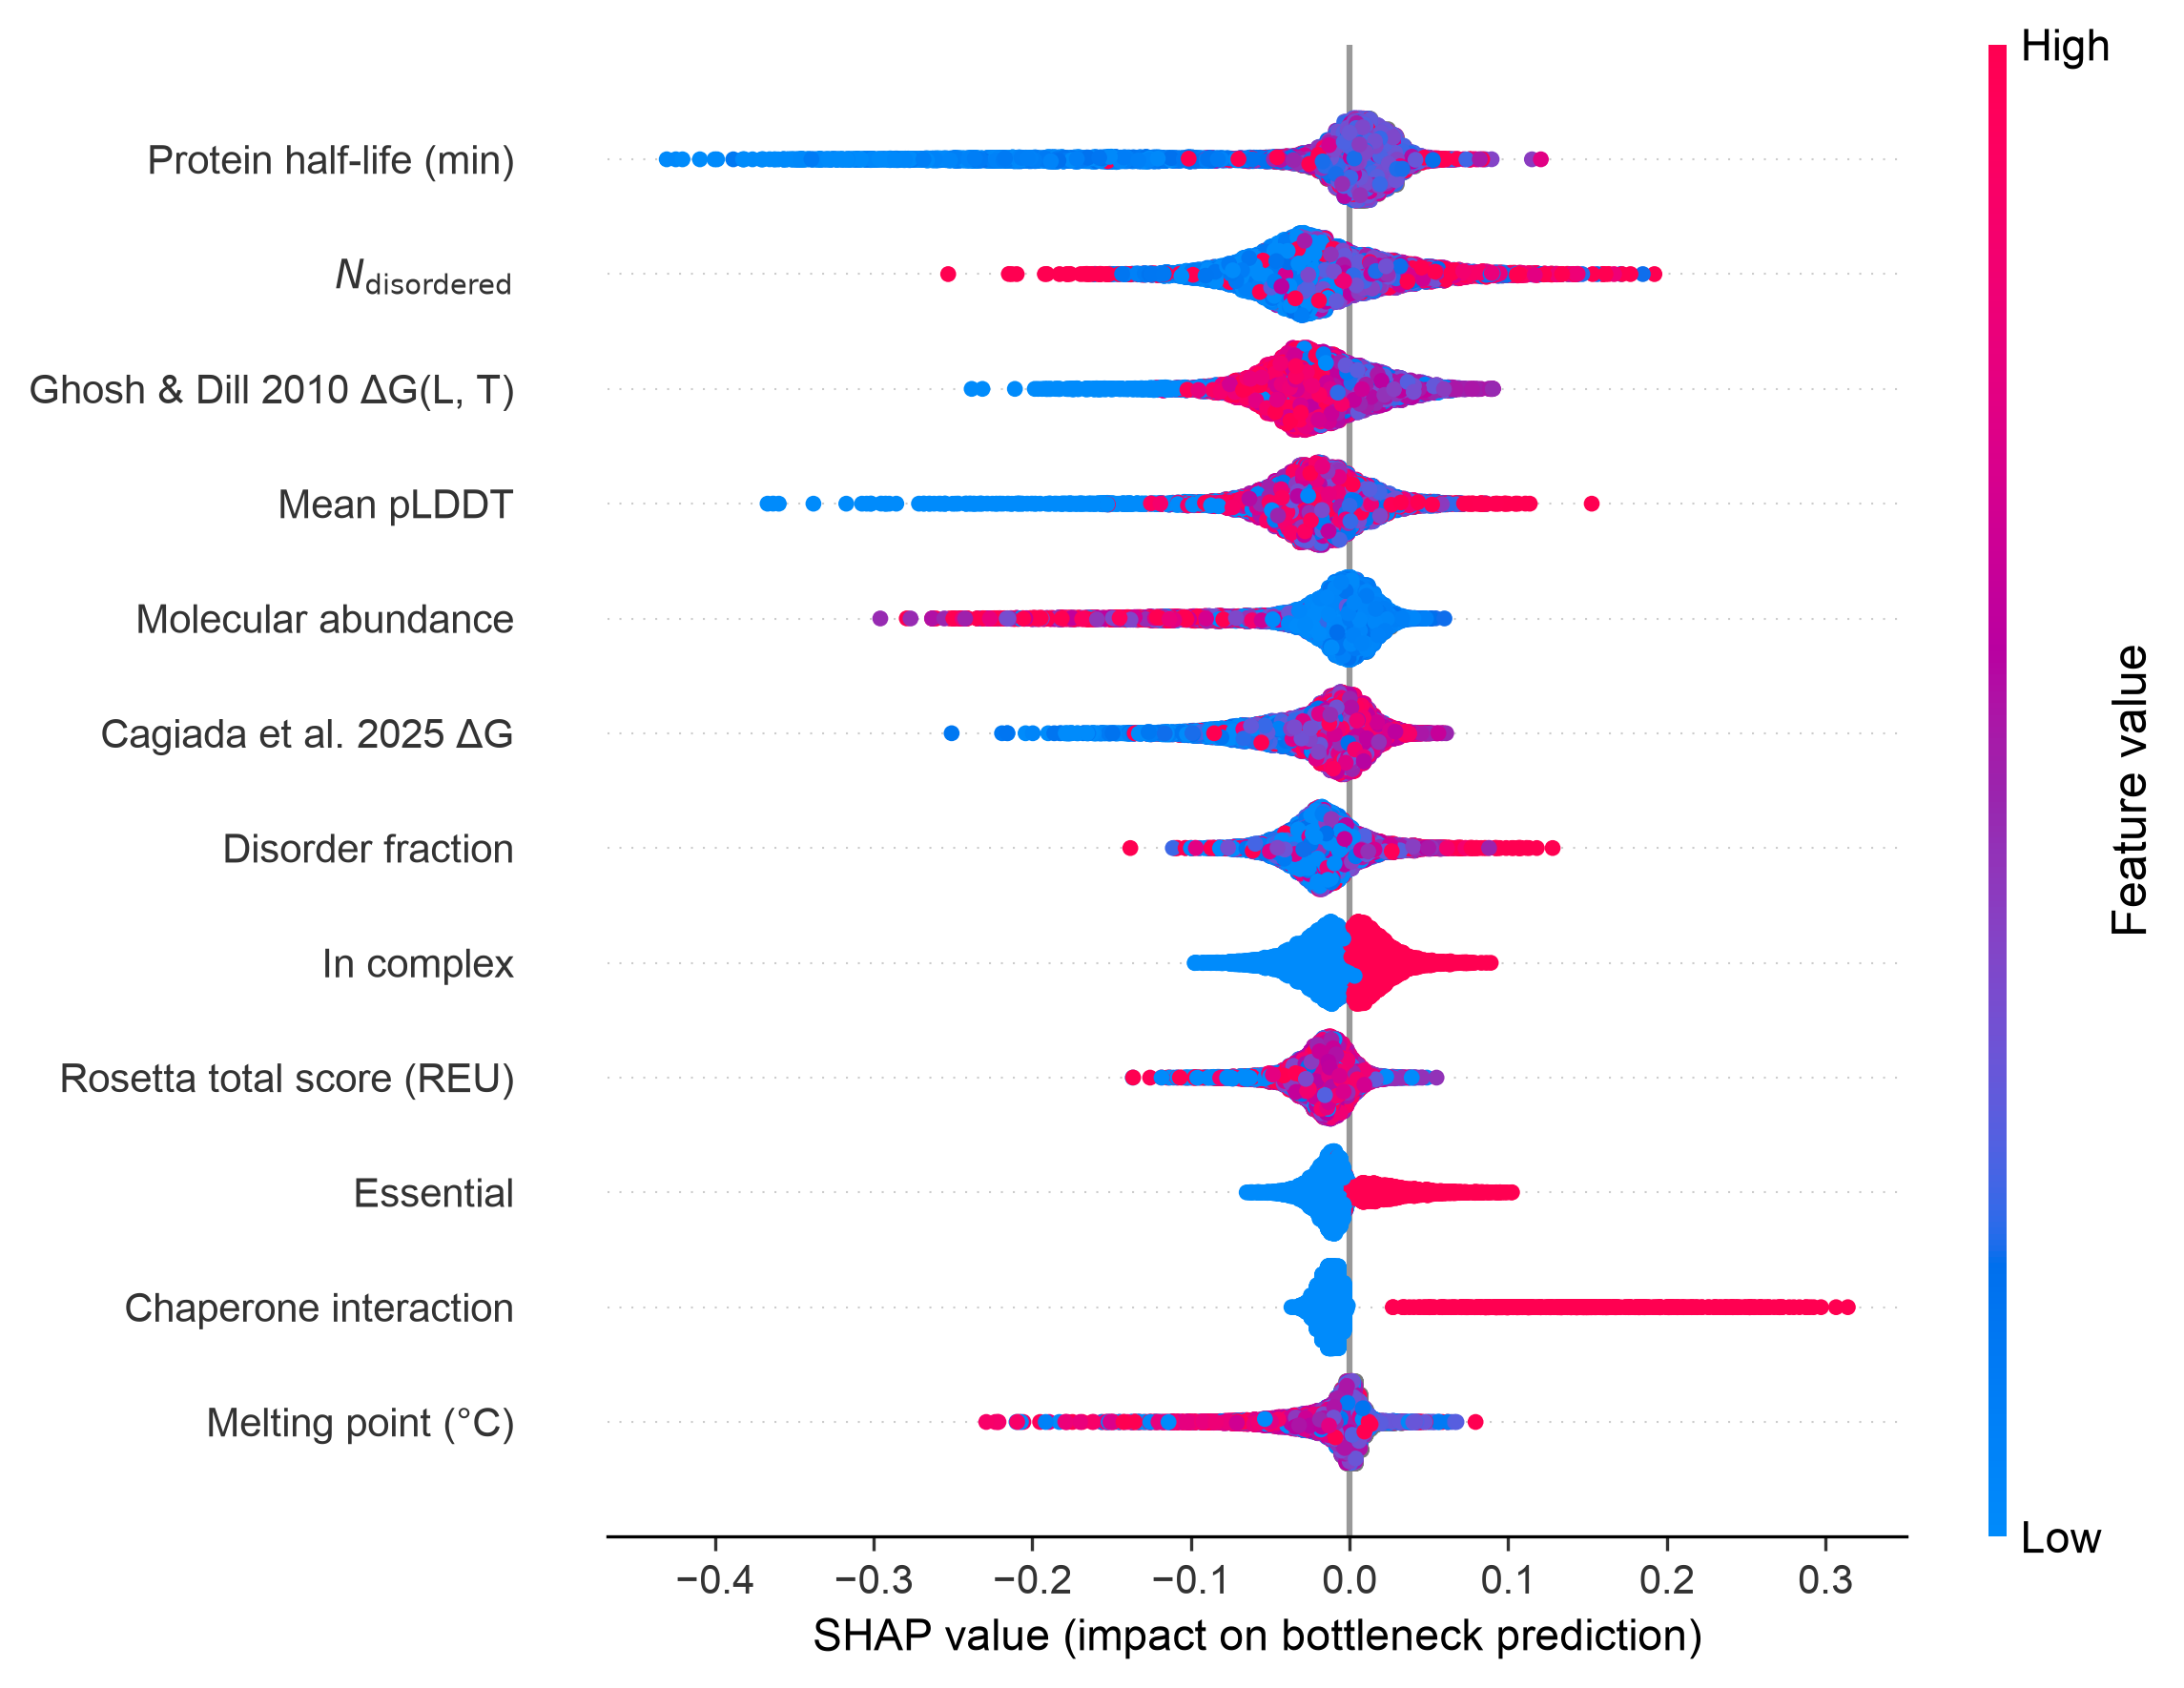

SHAP beeswarm plot generated successfully.
Total test-set predictions: 12700


In [17]:

# ============================================================
# POOLED SHAP BEESWARM ACROSS 50 MODELS
# Y2H betweennes centrality
# ============================================================

# 1. Combine test-set SHAP values across all models
pooled_shap_values = np.vstack(all_shap_values)

pooled_X_test = pd.concat(
    all_X_test,
    axis=0
)

# 2. Retrieve original feature values for visualization
# SHAP values remain calculated from imputed model inputs
assert X.index.is_unique

pooled_X_plot = X.loc[pooled_X_test.index].copy()

# 3. Verify matching dimensions
assert pooled_shap_values.shape == pooled_X_plot.shape

# 4. Prepare display names
display_names = [
    rename_map.get(f, f)
    for f in pooled_X_plot.columns
]

# 5. Generate SHAP beeswarm plot
shap.summary_plot(
    pooled_shap_values,
    pooled_X_plot,
    feature_names=display_names,
    plot_type="dot",
    max_display=12,
    plot_size=(8, 6),
    show=False
)

# 6. Format figure
fig = plt.gcf()
ax = plt.gca()

ax.set_xlabel(
    "SHAP value (impact on bottleneck prediction)",
    fontsize=11
)

ax.set_ylabel("")

ax.tick_params(
    axis="both",
    labelsize=10
)

plt.tight_layout()

# 7. Export figure
fig.savefig(
    "SHAP_Y2H_betweenness_50models.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

print("SHAP beeswarm plot generated successfully.")
print(f"Total test-set predictions: {len(pooled_X_plot)}")


Percentile: 70 | Threshold: 0.00081 | Hubs:  422 | ROC-AUC: 0.531 ± 0.035
Percentile: 75 | Threshold: 0.00090 | Hubs:  333 | ROC-AUC: 0.530 ± 0.033
Percentile: 80 | Threshold: 0.00162 | Hubs:  273 | ROC-AUC: 0.551 ± 0.035
Percentile: 85 | Threshold: 0.00242 | Hubs:  199 | ROC-AUC: 0.562 ± 0.049
Percentile: 90 | Threshold: 0.00366 | Hubs:  133 | ROC-AUC: 0.617 ± 0.051
Percentile: 95 | Threshold: 0.00643 | Hubs:   70 | ROC-AUC: 0.600 ± 0.064


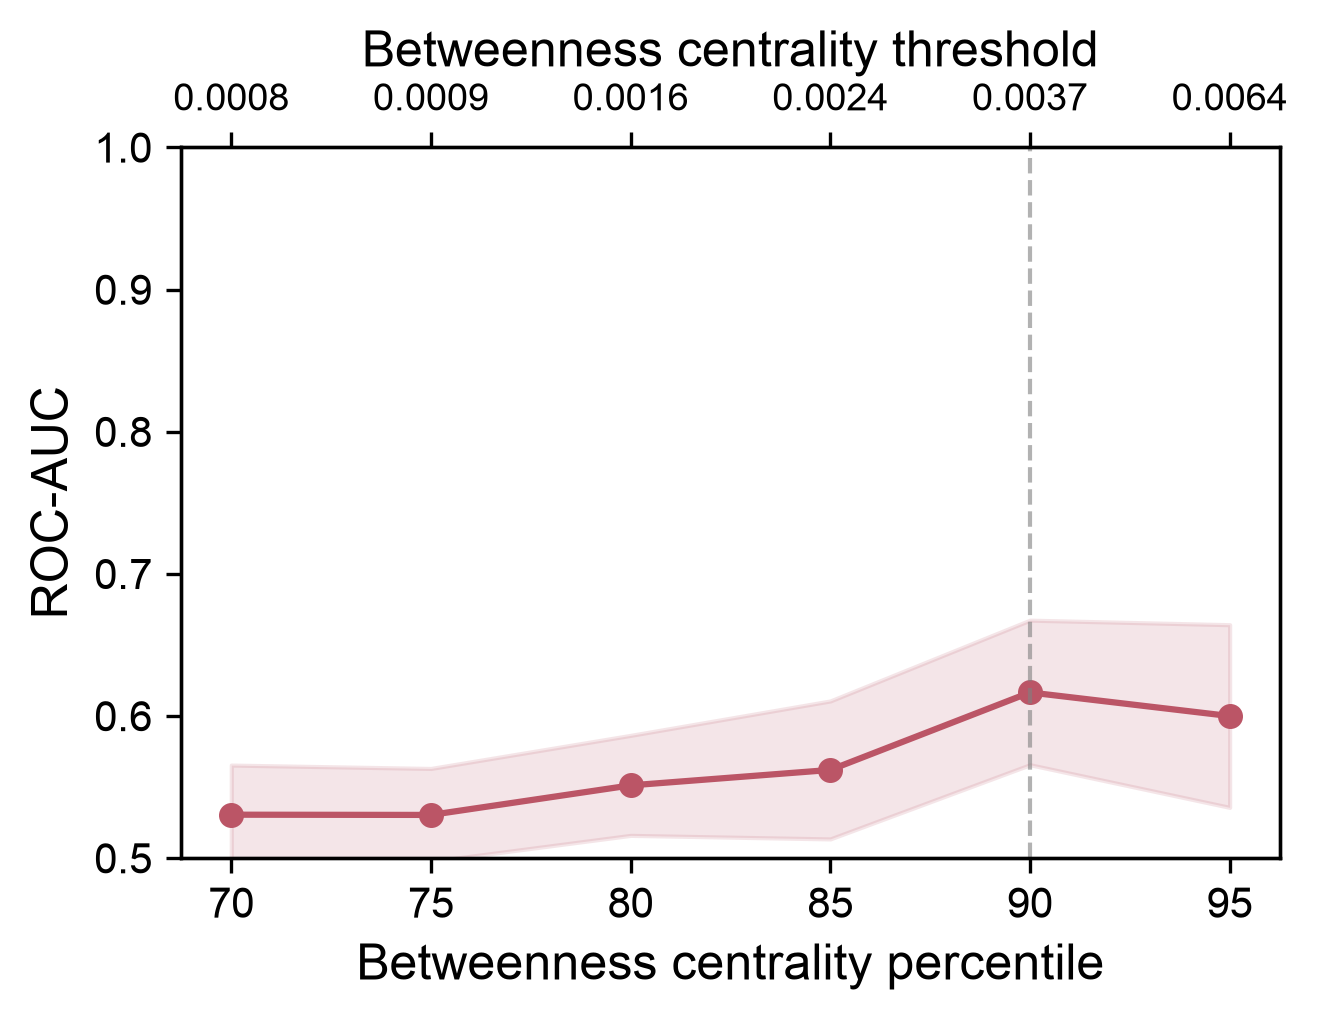

In [18]:

# ============================================================
# SUPPLEMENTARY ANALYSIS
# ROC-AUC ACROSS Betweenness-CENTRALITY PERCENTILE CUTOFFS
# ============================================================

def evaluate_betweenness_cutoffs(
    original_nodes,
    filtered_nodes,
    X_features,
    percentiles,
    n_repeats=50
):

    thresholds = []
    mean_aucs = []
    sd_aucs = []
    hub_counts = []

    for percentile in percentiles:

        # Calculate cutoff from the ORIGINAL Y2H network
        threshold = original_nodes["betweenness_centrality"].quantile(
            percentile / 100
        )

        # Create temporary target labels without modifying data
        y_cutoff = (
            filtered_nodes["betweenness_centrality"] >= threshold
        ).astype(int)

        # Reproduce the original 80/20 stratified split design
        splitter = StratifiedShuffleSplit(
            n_splits=n_repeats,
            test_size=0.2,
            random_state=42
        )

        aucs = []

        for i, (train_idx, test_idx) in enumerate(
            splitter.split(X_features, y_cutoff), start=1
        ):

            # Training-only median imputation
            imputer = SimpleImputer(strategy="median")

            X_train = imputer.fit_transform(
                X_features.iloc[train_idx]
            )

            X_test = imputer.transform(
                X_features.iloc[test_idx]
            )

            y_train = y_cutoff.iloc[train_idx]
            y_test = y_cutoff.iloc[test_idx]

            # Same hyperparameters as the primary model
            model = RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                min_samples_split=5,
                class_weight="balanced",
                random_state=42 + i
            )

            model.fit(X_train, y_train)

            probabilities = model.predict_proba(X_test)[:, 1]

            aucs.append(
                roc_auc_score(y_test, probabilities)
            )

        thresholds.append(threshold)
        mean_aucs.append(np.mean(aucs))
        sd_aucs.append(np.std(aucs, ddof=1))
        hub_counts.append(int(y_cutoff.sum()))

        print(
            f"Percentile: {percentile:2d} | "
            f"Threshold: {threshold:.5f} | "
            f"Hubs: {int(y_cutoff.sum()):4d} | "
            f"ROC-AUC: {np.mean(aucs):.3f} ± {np.std(aucs, ddof=1):.3f}"
        )

    return (
        np.array(thresholds),
        np.array(mean_aucs),
        np.array(sd_aucs),
        np.array(hub_counts)
    )


# ============================================================
# RUN CUTOFF SENSITIVITY ANALYSIS
# ============================================================

cutoff_percentiles = np.array([70, 75, 80, 85, 90, 95])

(
    cutoff_thresholds,
    cutoff_mean_auc,
    cutoff_sd_auc,
    cutoff_hub_counts
) = evaluate_betweenness_cutoffs(
    original_nodes=y2h_nodes,
    filtered_nodes=filtered_nodes,
    X_features=X,
    percentiles=cutoff_percentiles,
    n_repeats=50
)


# ============================================================
# PLOT: ROC-AUC VS BETWEENNESS-CENTRALITY CUTOFF
# ============================================================

fig, ax = plt.subplots(figsize=(4.5, 3.5))

ax.plot(
    cutoff_percentiles,
    cutoff_mean_auc,
    marker="o",
    markersize=5,
    linewidth=1.5,
    color=Y2H_COLOR
)

# +/- 1 SD across splits
ax.fill_between(
    cutoff_percentiles,
    np.clip(cutoff_mean_auc - cutoff_sd_auc, 0, 1),
    np.clip(cutoff_mean_auc + cutoff_sd_auc, 0, 1),
    color=Y2H_COLOR,
    alpha=0.15
)

# Highlight original 90th-percentile definition
ax.axvline(
    90,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

ax.set_xlabel("Betweenness centrality percentile", fontsize=12)
ax.set_ylabel("ROC-AUC", fontsize=12)

ax.set_xticks(cutoff_percentiles)
ax.set_ylim(0.5, 1.0)

# Secondary x-axis: actual centrality thresholds
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())
ax_top.set_xticks(cutoff_percentiles)

ax_top.set_xticklabels(
    [f"{value:.4f}" for value in cutoff_thresholds]
)

ax_top.set_xlabel(
    "Betweenness centrality threshold",
    fontsize=12
)

# Font cleanup
for text in fig.findobj(match=plt.Text):
    text.set_fontfamily("Arial")
    text.set_fontweight("normal")

ax.tick_params(axis="both", labelsize=10)
ax_top.tick_params(axis="x", labelsize=9)

plt.tight_layout()

"""
fig.savefig(
    "ROC_AUC_vs_Y2H_betweenness_cutoff.svg",
    format="svg",
    dpi=300,
    bbox_inches="tight"
)
"""

plt.show()


In [19]:

# ============================================================
# SUPPLEMENTARY: FULL BETWEENNESS-CENTRALITY CUTOFF SWEEP
# ============================================================

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.impute import SimpleImputer

def full_betweenness_cutoff_sweep(
    original_nodes,
    filtered_nodes,
    features,
    n_repeats=50,
    min_class_size=25
):

    # All unique raw betweenness_centrality values
    original_betweenness = original_nodes["betweenness_centrality"].dropna().to_numpy()
    unique_cutoffs = np.sort(np.unique(original_betweenness))

    # Storage (no new DataFrames)
    raw_values = []
    percentile_values = []
    mean_aucs = []
    sd_aucs = []
    hub_counts = []

    # Cache results when two cutoffs produce identical labels
    cache = {}

    assert features.index.equals(filtered_nodes.index)

    for threshold in unique_cutoffs:

        labels = (
            filtered_nodes["betweenness_centrality"] >= threshold
        ).astype(int)

        n_hubs = int(labels.sum())
        n_nonhubs = len(labels) - n_hubs

        # Exclude cutoffs with very small classes
        if min(n_hubs, n_nonhubs) < min_class_size:
            continue

        # Percentile position in ORIGINAL network
        percentile = 100 * np.mean(original_betweenness < threshold)

        if n_hubs not in cache:

            splitter = StratifiedShuffleSplit(
                n_splits=n_repeats,
                test_size=0.20,
                random_state=42
            )

            aucs = []

            for i, (train_idx, test_idx) in enumerate(
                splitter.split(features, labels), start=1
            ):

                imputer = SimpleImputer(strategy="median")

                X_train = imputer.fit_transform(
                    features.iloc[train_idx]
                )
                X_test = imputer.transform(
                    features.iloc[test_idx]
                )

                y_train = labels.iloc[train_idx]
                y_test = labels.iloc[test_idx]

                model = RandomForestClassifier(
                    n_estimators=200,
                    max_depth=10,
                    min_samples_split=5,
                    class_weight="balanced",
                    random_state=42 + i
                )

                model.fit(X_train, y_train)

                probabilities = model.predict_proba(X_test)[:, 1]

                aucs.append(
                    roc_auc_score(y_test, probabilities)
                )

            cache[n_hubs] = (
                np.mean(aucs),
                np.std(aucs, ddof=1)
            )

        mean_auc, sd_auc = cache[n_hubs]

        raw_values.append(threshold)
        percentile_values.append(percentile)
        mean_aucs.append(mean_auc)
        sd_aucs.append(sd_auc)
        hub_counts.append(n_hubs)

    return tuple(
        np.array(values)
        for values in (
            raw_values,
            percentile_values,
            mean_aucs,
            sd_aucs,
            hub_counts
        )
    )


# ============================================================
# RUN INDEPENDENT SUPPLEMENTARY ANALYSIS
# ============================================================

(
    sweep_raw,
    sweep_percentile,
    sweep_auc,
    sweep_sd,
    sweep_hubs
) = full_betweenness_cutoff_sweep(
    original_nodes=y2h_nodes,
    filtered_nodes=filtered_nodes,
    features=X,
    n_repeats=50,
    min_class_size=25
)

print(f"Number of evaluated cutoffs: {len(sweep_raw)}")
print(f"Original 90th-percentile threshold: {y2h_threshold:.5f}")
print(f"Original model ROC-AUC: {results_df['roc_auc'].mean():.3f}")

Number of evaluated cutoffs: 646
Original 90th-percentile threshold: 0.00366
Original model ROC-AUC: 0.617


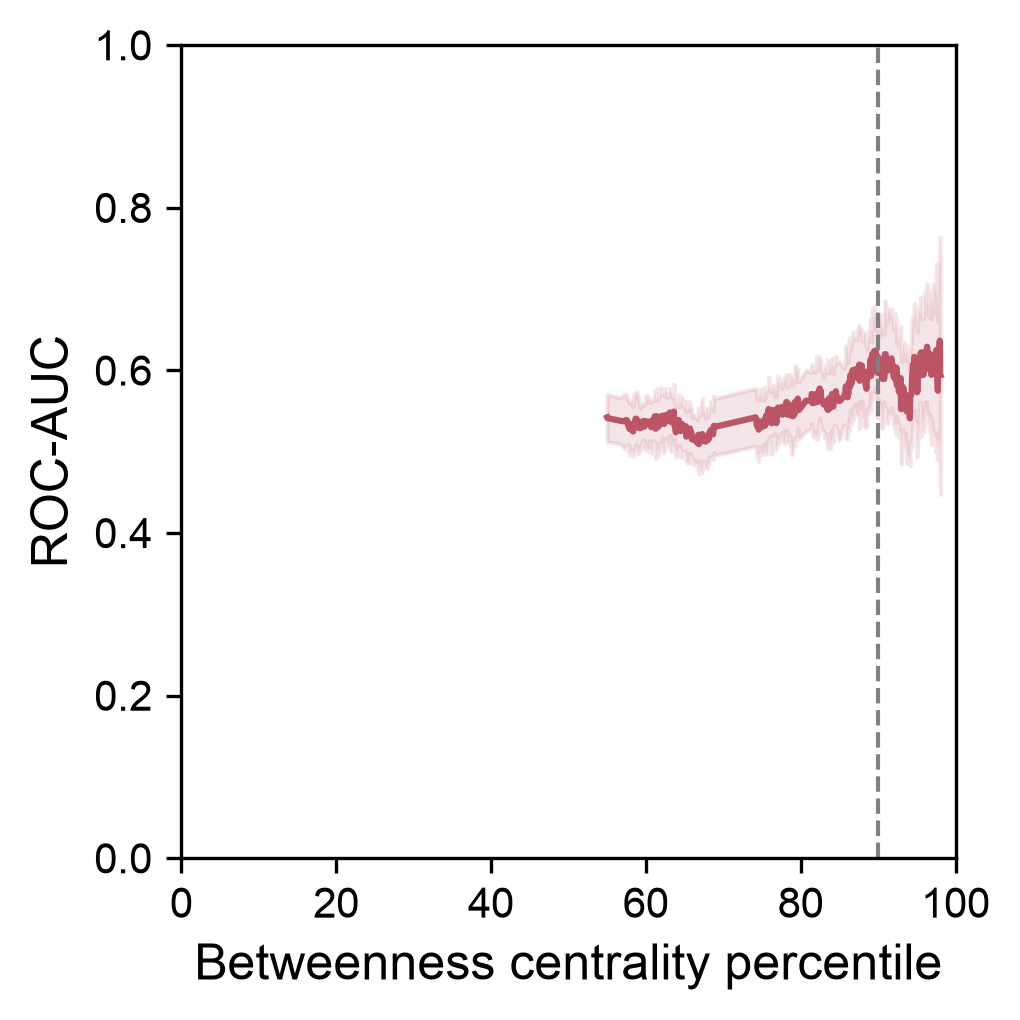

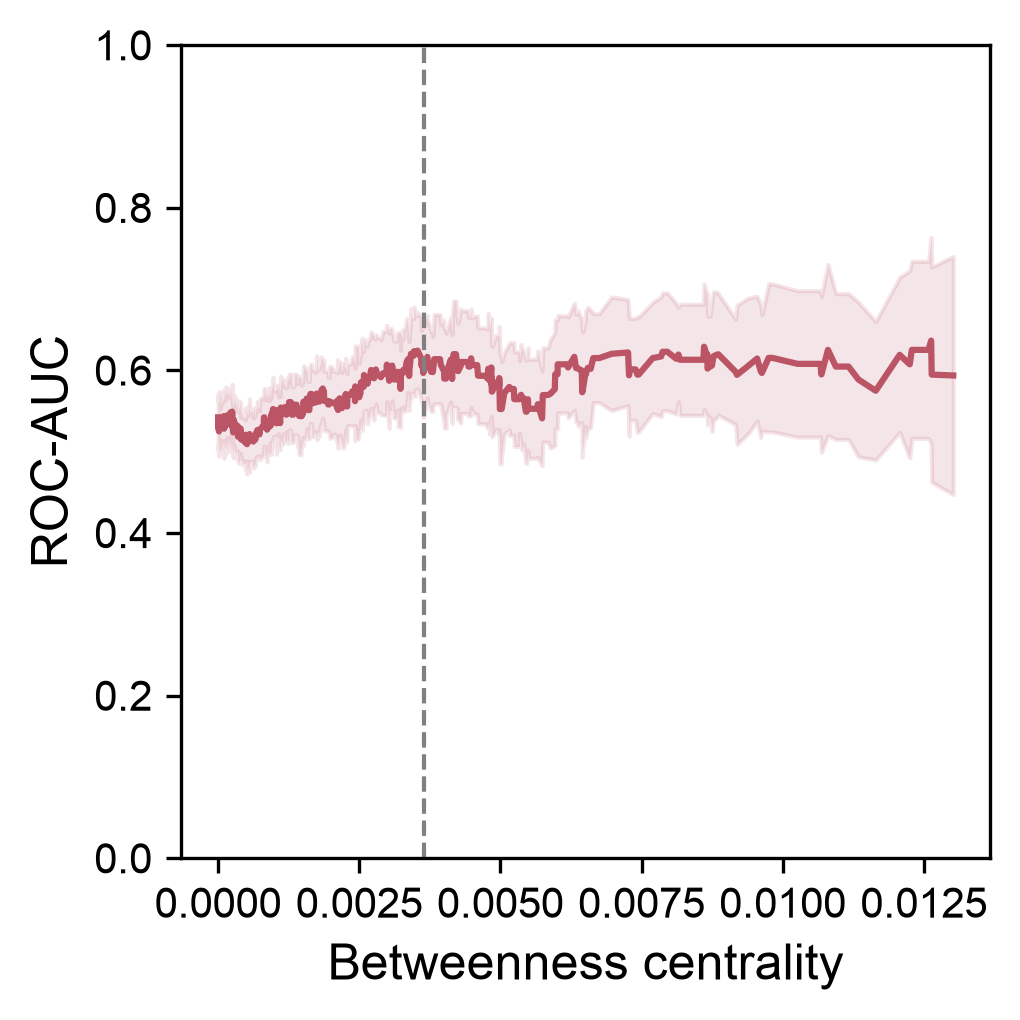

In [20]:
# ============================================================
# FIGURE A: ROC-AUC VS BETWEENNESS-CENTRALITY PERCENTILE
# ============================================================

fig, ax = plt.subplots(figsize=(3.5, 3.5))

ax.plot(
    sweep_percentile,
    sweep_auc,
    color=Y2H_COLOR,
    linewidth=1.5
)

ax.fill_between(
    sweep_percentile,
    np.clip(sweep_auc - sweep_sd, 0, 1),
    np.clip(sweep_auc + sweep_sd, 0, 1),
    color=Y2H_COLOR,
    alpha=0.15
)

ax.axvline(90, color="gray", linestyle="--", linewidth=1)

ax.set_xlabel("Betweenness centrality percentile", fontsize=12)
ax.set_ylabel("ROC-AUC", fontsize=12)
ax.set_xlim(0, 100)
ax.set_ylim(0, 1)

ax.tick_params(labelsize=10)
plt.tight_layout()

"""
fig.savefig(
    "ROC_AUC_vs_Y2H_betweenness_percentile.svg",
    format="svg",
    dpi=300,
    bbox_inches="tight"
)
"""

plt.show()


# ============================================================
# FIGURE B: ROC-AUC VS RAW BETWEENNESS CENTRALITY
# ============================================================

fig, ax = plt.subplots(figsize=(3.5, 3.5))

ax.plot(
    sweep_raw,
    sweep_auc,
    color=Y2H_COLOR,
    linewidth=1.5
)

ax.fill_between(
    sweep_raw,
    np.clip(sweep_auc - sweep_sd, 0, 1),
    np.clip(sweep_auc + sweep_sd, 0, 1),
    color=Y2H_COLOR,
    alpha=0.15
)

ax.axvline(
    y2h_threshold,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Betweenness centrality", fontsize=12)
ax.set_ylabel("ROC-AUC", fontsize=12)
ax.set_ylim(0, 1)

ax.tick_params(labelsize=10)
plt.tight_layout()

"""
fig.savefig(
    "ROC_AUC_vs_Y2H_raw_betweenness.svg",
    format="svg",
    dpi=300,
    bbox_inches="tight"
)
"""

plt.show()
